# 4 - Overview of the session

In [1]:
import os

# go to the project root, then run the reading part to get the data
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

%run notebooks/01_reading.ipynb

Header line information in 'data/001MoDe_R1.csv':
  screenWidth: 1104.0
  screenHeight: 661.0
  cornerX: 302.0
  cornerY: 80.0
  centerX: 552.0
  centerY: 330.0
  externalRadius: 250.0
  internalRadius: 170.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 28.00696429476858
  taskRadius: 209.5
  taskTolerance: 47.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  software: LSL-mouse
  version: 1.2.0rc5
  task: CircularTarget
  isWithLSL: false
Same header in both files: True
Markers in 'data/001MoDe_R1.marker.csv':
1616776712325: KeyTyped=32 DoCycleChange
1616776712331: DoCycleChange:DoStartCycleTimedSequence
1616776712333: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1616776732336: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1616776752340: 

### Raw time series data
Position of the mouse over the whole session, in centered coordinates: the center of the circle is at (0, 0), and the y axis points up (on the screen, y points down, so we use center Y - y).
Black dashed lines = start of each record (DoRecord), red dashed lines = end (DoPause).

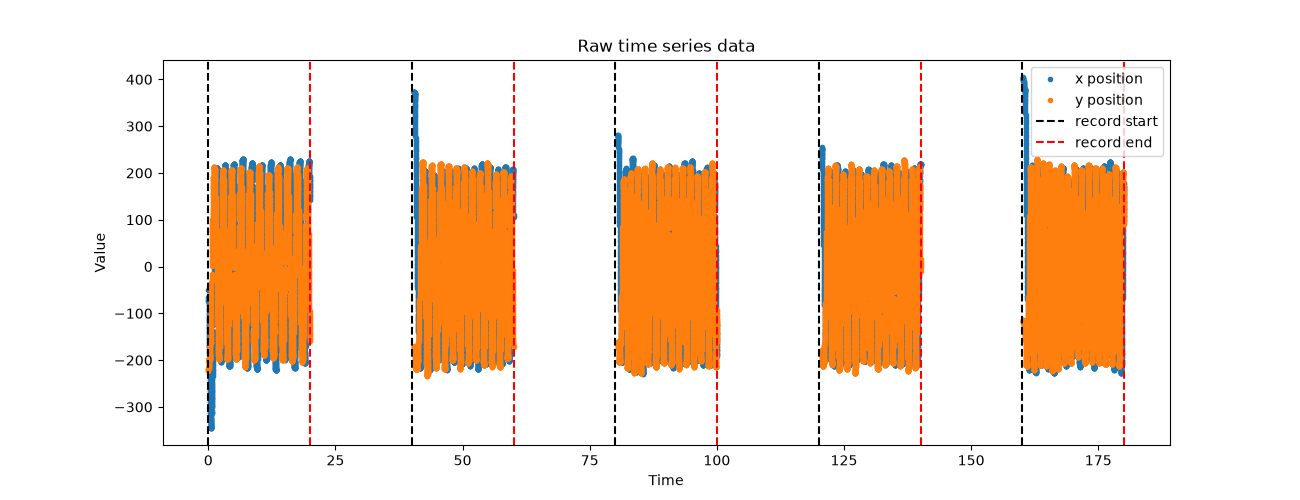

In [5]:
# centered coordinates: center of the circle = (0, 0), y axis pointing up
x_c = x - params["centerX"]
y_c = params["centerY"] - y

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(t, x_c, ".", label="x position")
ax.plot(t, y_c, ".", label="y position")

# vertical lines at the start (black) and end (red) of each record
for i in range(n_records):
    ax.axvline(t_starts[i], color="black", linestyle="--", label="record start" if i == 0 else None)
    ax.axvline(t_ends[i], color="red", linestyle="--", label="record end" if i == 0 else None)

ax.set_title("Raw time series data")
ax.set_xlabel("Time")
ax.set_ylabel("Value")
ax.legend()
plt.show()

### Explanation : 
We can see 5 records of about 20 s, separated by pauses of about 20 s without data: in this version of MouseReMoCo (1.2), the mouse position is only recorded during the records.
The 6th record planned in the configuration is missing because "q" was pressed during the 5th pause.

In each record, x and y oscillate between about -210 and +210 px around 0 (the center of the circle).
This is what a circular movement looks like when x and y are plotted separately : one oscillation = one lap. The amplitude (about 210 px) matches the task radius (taskRadius = 209.5 px).
The number of oscillations increases from about 11 in record 1 to about 15 in record 5: the participant becomes faster (1.84 s per lap in record 1, 1.30 s in record 5).

At the beginning of each record, x goes beyond the circle (down to about -340 px in record 1, up to about +400 px in record 5): the cursor is not yet in the target when the record starts.
This is why the statistics are only computed after the cursor enters the target for the first time.